# Workshop 2 - Historical pipeline review

**Team 9: Kevin David Rincon Valencia and Pablo Garzon Gomez**

We read three Parquet files produced by successful Airflow runs. The purpose is
to check the saved output with Pandas: records, types, missing values, units and
provenance. This notebook makes no API or database calls.

The samples cover Oklahoma Storm Events in 2021 and one Oklahoma City GHCN
station in 2021/2022. The separate database receipt describes the full executed
2021-2025 slice. Station samples are not statewide weather coverage.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents]
            if (p / "workshop_2/samples/manifest.json").exists()
            or (p / "samples/manifest.json").exists())
samples = root / "workshop_2/samples" if (root / "workshop_2").exists() else root / "samples"
evidence = root / "workshop_2/evidence" if (root / "workshop_2").exists() else root / "evidence"
manifest = json.loads((samples / "manifest.json").read_text())
print("Python:", sys.version.split()[0], "| Pandas:", pd.__version__)
print("Samples:", len(manifest["entries"]))

Python: 3.12.16 | Pandas: 3.1.1
Samples: 3


## 1. Check the files before reading

The manifest records the SHA-256 and size of each packaged file. A changed file
must fail this check rather than silently produce different results.

In [2]:
for name, expected in manifest["files"].items():
    body = (samples / name).read_bytes()
    assert hashlib.sha256(body).hexdigest().upper() == expected["sha256"], name
    assert len(body) == expected["bytes"], name
print("All packaged hashes and sizes match.")

All packaged hashes and sizes match.


## 2. Read a Parquet as a DataFrame

Each output contains accepted records for one ingestion run. GHCN has one row
per station, date and element; Storm Events has one row per source event ID.

In [3]:
frames = {}
for entry in manifest["entries"]:
    df = pd.read_parquet(samples / entry["silver"])
    assert len(df) == entry["metrics"]["accepted"] + entry["metrics"]["unchanged"]
    frames[entry["partition"]] = df

storms = frames["OK_2021"]
daily = pd.concat([df for key, df in frames.items() if key.startswith("USW")], ignore_index=True)
display(storms.head())
display(daily[["source_key", "observed_date", "event_type", "severity_value", "severity_unit"]].head())

,record_id,source,source_key,event_type,observed_at_utc,observed_date,latitude,longitude,severity_value,severity_unit,magnitude_type,quality_attributes,source_content_sha256,capture_sha256,run_id,capture_id,source_line,revision_id
0,1346,noaa_storm_events,972782,Flood,2021-07-01 17:02:00+00:00,None,35.6709,-97.5260,NaN,NaN,NaN,NaN,38657c58f9b536f9c38521e908aef36647789d95c0498b...,78fb408f7be505b6ad51df631659f7dd70edada826b240...,16,16,2,6131
1,1347,noaa_storm_events,972783,Thunderstorm Wind,2021-07-01 18:15:00+00:00,None,35.3400,-96.9200,52.0,kn,MG,NaN,578e83c6bb420bf09eead11d00365864910852868134b6...,78fb408f7be505b6ad51df631659f7dd70edada826b240...,16,16,3,6132
2,1348,noaa_storm_events,972784,Flood,2021-07-01 21:15:00+00:00,None,35.2077,-97.4501,NaN,NaN,NaN,NaN,79220214ec8e20dee5f50eb1da05d04b9a7f3ce1b1006a...,78fb408f7be505b6ad51df631659f7dd70edada826b240...,16,16,4,6133
3,1349,noaa_storm_events,972785,Flood,2021-07-01 21:16:00+00:00,None,35.2140,-97.4530,NaN,NaN,NaN,NaN,00a78f68bef89bd9af7b6f851c426539740b11c9a1470b...,78fb408f7be505b6ad51df631659f7dd70edada826b240...,16,16,5,6134
4,1350,noaa_storm_events,972786,Flash Flood,2021-07-07 22:30:00+00:00,None,36.4262,-97.8802,NaN,NaN,NaN,NaN,66e9ee89d339b8dca2a602a3e30ace1b2f2465a391bc12...,78fb408f7be505b6ad51df631659f7dd70edada826b240...,16,16,6,6135


,source_key,observed_date,event_type,severity_value,severity_unit
0,USW00013967/2021-01-01/PRCP,2021-01-01,PRCP,15.2,mm
1,USW00013967/2021-01-01/TMAX,2021-01-01,TMAX,1.1,degC
2,USW00013967/2021-01-01/TMIN,2021-01-01,TMIN,-1.0,degC
3,USW00013967/2021-01-02/PRCP,2021-01-02,PRCP,0.3,mm
4,USW00013967/2021-01-02/TMAX,2021-01-02,TMAX,5.6,degC


In [4]:
storms.info()
display(daily.dtypes.to_frame("dtype"))
display(daily.groupby(["event_type", "severity_unit"])["severity_value"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   record_id              1324 non-null   int64              
 1   source                 1324 non-null   str                
 2   source_key             1324 non-null   str                
 3   event_type             1324 non-null   str                
 4   observed_at_utc        1324 non-null   datetime64[us, UTC]
 5   observed_date          0 non-null      object             
 6   latitude               767 non-null    float64            
 7   longitude              767 non-null    float64            
 8   severity_value         613 non-null    float64            
 9   severity_unit          613 non-null    str                
 10  magnitude_type         354 non-null    str                
 11  quality_attributes     0 non-null      str                
 12  sou

,dtype
record_id,int64
source,str
source_key,str
event_type,str
observed_at_utc,"datetime64[us, UTC]"
observed_date,object
latitude,float64
longitude,float64
severity_value,float64
severity_unit,str


,,count,mean,std,min,25%,50%,75%,max
event_type,severity_unit,,,,,,,,
PRCP,mm,730.0,2.015205,7.163595,0.0,0.0,0.0,0.0,74.7
TMAX,degC,730.0,22.552877,10.508779,-15.5,15.6,23.9,31.1,43.3
TMIN,degC,730.0,9.581781,10.212630,-25.5,1.7,10.0,18.9,27.8


## 3. Missing fields and time grain

GHCN dates are daily observations, so `observed_at_utc` is intentionally null.
Storm Events keeps the UTC instant and may have no point coordinates. Missing
coordinates are retained with source geography in the database; no point or
midnight timestamp is invented. Missing optional measurements are not imputed.

In [5]:
all_samples = pd.concat(frames.values(), ignore_index=True)
display(all_samples.groupby("source").size().to_frame("records"))
display(all_samples.isna().sum().to_frame("missing"))
assert daily["observed_at_utc"].isna().all()
assert daily["observed_date"].notna().all()
assert storms["observed_at_utc"].notna().all()
assert storms["observed_date"].isna().all()
assert (all_samples["latitude"].isna() == all_samples["longitude"].isna()).all()

,records
source,
ghcn_daily,2190
noaa_storm_events,1324


,missing
record_id,0
source,0
source_key,0
event_type,0
observed_at_utc,2190
observed_date,1324
latitude,557
longitude,557
severity_value,711
severity_unit,711


## 4. Keys, units and quality attributes

Only like units are compared. Hail magnitude is in inches; wind is in knots;
GHCN temperatures and precipitation were requested in metric units. Original
GHCN attribute strings are preserved. A nonempty quality flag requires review,
and is not automatically treated as a new hazard event.

In [6]:
duplicates = all_samples.duplicated(["source", "source_key"]).sum()
assert duplicates == 0
display(all_samples.groupby(["source", "event_type", "severity_unit"], dropna=False).size().to_frame("records"))
attributes = daily["quality_attributes"].fillna("")
quality_flag = attributes.str.split(",").str[1].fillna("")
display(quality_flag.value_counts(dropna=False).rename_axis("GHCN quality flag").to_frame("records"))
print("Duplicate business keys:", duplicates)

records
source            event_type              severity_unit         
ghcn_daily        PRCP                    mm                 730
                  TMAX                    degC               730
                  TMIN                    degC               730
noaa_storm_events Cold/Wind Chill         NaN                 49
                  Drought                 NaN                214
                  Dust Storm              NaN                  1
                  Excessive Heat          NaN                 51
                  Extreme Cold/Wind Chill NaN                  3
                  Flash Flood             NaN                103
                  Flood                   NaN                 40
                  Freezing Fog            NaN                  1
                  Hail                    in                 259
                  Heat                    NaN                 10
                  Heavy Snow              NaN                 81
                  High Wind               kn                  56
                  Strong Wind             kn                   1
                  Thunderstorm Wind       kn                 297
                  Tornado                 NaN                 68
                  Wildfire                NaN                 38
                  Winter Storm            NaN                 48
                  Winter Weather          NaN                  4

,records
GHCN quality flag,
,2190


Duplicate business keys: 0


## 5. Distribution review

We use a boxplot and the 1.5-IQR rule separately for each daily variable. These
are review flags, not deletion criteria: extreme rain or temperature may be the
signal this project needs. Values and sample counts remain unchanged.

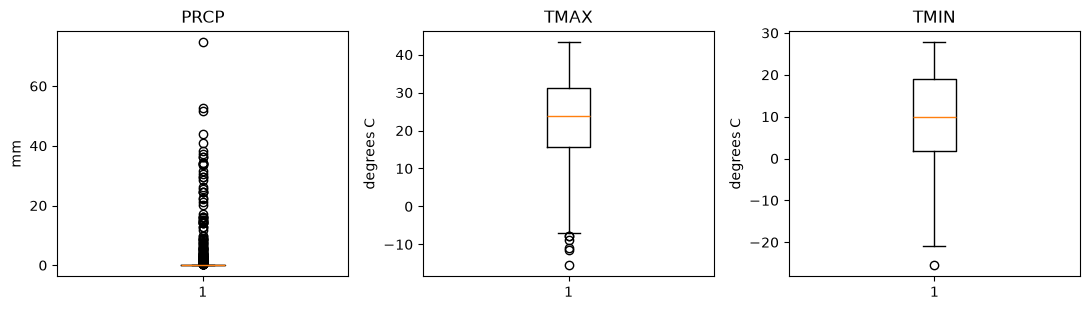

,element,n,review_flags,lower_fence,upper_fence
0,PRCP,730,146,0.00,0.00
1,TMAX,730,6,-7.65,54.35
2,TMIN,730,1,-24.10,44.70


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
iqr_review = []
for ax, element in zip(axes, ["PRCP", "TMAX", "TMIN"]):
    values = daily.loc[daily["event_type"].eq(element), "severity_value"].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr))
    ax.boxplot(values)
    ax.set_title(element)
    ax.set_ylabel("mm" if element == "PRCP" else "degrees C")
    iqr_review.append({"element": element, "n": len(values), "review_flags": int(flagged.sum()),
                       "lower_fence": q1 - 1.5 * iqr, "upper_fence": q3 + 1.5 * iqr})
plt.tight_layout()
plt.show()
display(pd.DataFrame(iqr_review))

## 6. Follow one record back to Bronze

The Parquet row stores a CSV line number and capture hash. For GHCN, multiple
measurements refer to the same daily CSV row. The Bronze JSON is a parsed view;
the packaged CSV bytes remain separate. NOAA's CSV is an explicitly documented
Oklahoma subset of the preserved nationwide gzip response.

In [8]:
entry = manifest["entries"][0]
bronze = json.loads((samples / entry["bronze"]).read_text())
record = frames[entry["partition"]].iloc[0]
source_row = bronze["rows"][int(record["source_line"]) - 2]
assert str(source_row["EVENT_ID"]) == record["source_key"]
assert record["capture_sha256"].upper() == bronze["original_capture"]["sha256"].upper()
display(pd.Series({"event_id": source_row["EVENT_ID"], "event_type": source_row["EVENT_TYPE"],
                   "source_line": int(record["source_line"]), "run_id": int(record["run_id"]),
                   "capture_sha256": record["capture_sha256"]}))

event_id                                                     972782
event_type                                                    Flood
source_line                                                       2
run_id                                                           16
capture_sha256    78fb408f7be505b6ad51df631659f7dd70edada826b240...
dtype: object

## 7. Full historical slice and quarantine evidence

This section reads the captured database audit rather than opening a live
connection. The acquisition window is 2021-2025. The semester target remains
2010-2025, and adding stations and reviewed county assignments remains open.
Zero rejected rows in these inputs does not mean the rejection path was untested:
integration fixtures exercise quarantine and transaction rollback separately.

In [9]:
database = json.loads((evidence / "delivery_database.json").read_text())
display(pd.DataFrame(database["sources"]))
display(pd.DataFrame(database["daily_years"]))
display(pd.DataFrame(database["event_years"]))
assert not database["duplicate_business_keys"]
tests = json.loads((evidence / "wsl_test_results.json").read_text())
assert tests["successful"] and not tests["skipped"]
print("Verified tests:", tests["passed"], "| No live calls were made by this notebook.")

,source_id,records,first_date,last_date,missing_point
0,ghcn_daily,5478,2021-01-01,2025-12-31,0
1,noaa_storm_events,13561,2021-01-01,2025-12-23,7084


,year,days,measurements,stations
0,2021,365,1095,1
1,2022,365,1095,1
2,2023,365,1095,1
3,2024,366,1098,1
4,2025,365,1095,1


,year,events,oklahoma_events
0,2021,1324,1324
1,2022,2077,2077
2,2023,3764,3764
3,2024,3504,3504
4,2025,2892,2892


Verified tests: 29 | No live calls were made by this notebook.


## 8. Review result

The packaged samples reconcile with their run metrics and hashes. Units and
daily/instant time grains remain explicit. We preserve weather extremes, missing
point locations and source flags rather than filling them with invented values.
The database evidence and Airflow receipts are technical checks, not personal
approval or confirmation of submission.